# Análisis Exploratorio de Datos (EDA)
## Predicción del tiempo de entrega de pedidos de comida

**Proyecto:** FoodDeliveryML  
**Diplomatura:** Inteligencia Artificial — Universidad de Palermo  
**Dataset:** Food Delivery Time Prediction Dataset

### 1. Introducción

El presente notebook desarrolla un análisis exploratorio de datos (Exploratory Data Analysis, EDA) sobre un conjunto de 50.000 registros correspondientes a pedidos de entrega de comida.

El objetivo principal es identificar patrones, relaciones y características estadísticas que permitan comprender los factores asociados con el tiempo de entrega de los pedidos.

El análisis contempla:

- Distribución de las principales variables numéricas.
- Identificación de posibles valores atípicos.
- Comparación de tiempos de entrega entre categorías.
- Análisis de relaciones entre variables.
- Estudio de correlaciones.
- Evaluación de hipótesis previamente formuladas.
- Elaboración de conclusiones fundamentadas en los resultados.

El dataset fue sometido previamente a un proceso de evaluación de calidad y consistencia, documentado en `01_data_understanding.ipynb`.

La variable objetivo es `Time_taken_min`, que representa el tiempo de entrega expresado en minutos.

Este análisis es exploratorio y observacional. Por lo tanto, las asociaciones identificadas no deben interpretarse automáticamente como relaciones causales.

## 2. Hipótesis de investigación

Antes de realizar el análisis exploratorio, se establecen cinco hipótesis que orientarán la selección de variables, visualizaciones e interpretaciones.

### Hipótesis 1 — Distancia y tiempo de entrega

A mayor distancia recorrida entre el restaurante y el destino, mayor será el tiempo de entrega del pedido.

**Variables:** `Road_Distance_km` y `Time_taken_min`.

### Hipótesis 2 — Congestión del tráfico

Los pedidos realizados bajo condiciones de tráfico elevado presentan mayores tiempos de entrega que aquellos realizados con tráfico reducido.

**Variables:** `Traffic_Level` y `Time_taken_min`.

### Hipótesis 3 — Tiempo de preparación

Un mayor tiempo de preparación del pedido se asocia con un incremento del tiempo total de entrega.

**Variables:** `Preparation_Time_Min` y `Time_taken_min`.

### Hipótesis 4 — Velocidad promedio

Una mayor velocidad promedio de desplazamiento se asocia con menores tiempos de entrega.

**Variables:** `Average_Speed_kmph` y `Time_taken_min`.

Esta variable se analizará descriptivamente, aunque su disponibilidad al momento de realizar una predicción deberá evaluarse posteriormente para evitar posibles fugas de información.

### Hipótesis 5 — Condiciones operativas y temporales

El tiempo de entrega presenta diferencias según las condiciones operativas y temporales, particularmente el clima, la carga del restaurante, la prioridad del pedido y la hora del día.

**Variables:** `Weather`, `Restaurant_Load`, `Delivery_Priority`, `Order_Hour` y `Time_taken_min`.

### Criterio de evaluación

Cada hipótesis será examinada mediante estadísticas descriptivas y visualizaciones apropiadas.

Las conclusiones distinguirán entre hipótesis respaldadas por la evidencia descriptiva, parcialmente respaldadas y no respaldadas.

## 3. Configuración del entorno

Se importan las librerías necesarias para la manipulación, el análisis estadístico descriptivo y la visualización de los datos.

Se establece una configuración gráfica uniforme para facilitar la interpretación y comparación de los resultados.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configuración general
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

RANDOM_STATE = 42

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 4. Carga y verificación del dataset

Se utiliza el dataset preparado en la etapa anterior, preservando el archivo original.

Se comprueba su disponibilidad, dimensiones, tipos de datos y presencia de valores faltantes antes de iniciar el análisis exploratorio.

In [2]:
# Ruta relativa desde la carpeta notebooks
DATA_PATH = Path("../data/processed/food_delivery_prepared.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el dataset preparado: {DATA_PATH.resolve()}"
    )

# Carga con interpretación explícita de fechas
df = pd.read_csv(
    DATA_PATH,
    parse_dates=["Order_Date"]
)

TARGET = "Time_taken_min"

print("Dataset cargado correctamente.")
print(f"Registros: {df.shape[0]:,}")
print(f"Variables: {df.shape[1]}")
print(f"Tipo de Order_Date: {df['Order_Date'].dtype}")
print(f"Valores faltantes: {df.isna().sum().sum():,}")

display(df.head())

Dataset cargado correctamente.
Registros: 50,000
Variables: 24
Tipo de Order_Date: datetime64[us]
Valores faltantes: 0


,Order_ID,Order_Date,Order_Hour,Day_of_Week,Is_Weekend,Is_Festival,Weather,Pickup_Zone,Dropoff_Zone,Vehicle_Type,Rider_Experience_Years,Rider_Rating,Restaurant_Rating,Cuisine_Type,Order_Items,Restaurant_Load,Preparation_Time_Min,Road_Distance_km,Delivery_Distance_Category,Traffic_Level,Number_of_Signals,Average_Speed_kmph,Delivery_Priority,Time_taken_min
0,ORD000001,2025-10-28,8,Tuesday,0,0,Clear,CBD,Commercial,Scooter,3.10,3.80,3.80,Pizza,1,Medium,23,30.55,Long,Moderate,15,28.70,Normal,91
1,ORD000002,2025-09-26,12,Friday,0,0,Rain,CBD,CBD,Scooter,1.80,3.60,3.90,Desserts,3,Medium,11,2.25,Short,Moderate,17,23.30,Normal,21
2,ORD000003,2025-01-26,18,Sunday,1,0,Clear,Residential,Residential,Scooter,3.80,3.90,4.00,Biryani,1,Low,31,10.15,Long,Moderate,8,28.90,Normal,52
3,ORD000004,2025-11-19,12,Wednesday,0,0,Cloudy,Residential,Industrial,Bike,1.70,3.90,4.60,Burger,3,Medium,19,26.33,Long,Low,9,41.40,Normal,59
4,ORD000005,2025-08-04,18,Monday,0,0,Rain,Industrial,Residential,Bike,12.40,4.40,4.00,Desserts,1,Medium,7,30.48,Long,Moderate,8,31.70,Normal,75


## 5. Análisis descriptivo inicial

Se calculan estadísticas descriptivas para las variables numéricas, incluyendo medidas de tendencia central, dispersión y posición.

Esta evaluación proporciona una primera aproximación a la variabilidad de los datos y permite identificar variables que requieren un análisis visual más detallado.

In [3]:
# Resumen estadístico de variables numéricas
resumen_estadistico = df.describe().T

display(resumen_estadistico)

# Estadísticas específicas de la variable objetivo
print("\n=== VARIABLE OBJETIVO: TIEMPO DE ENTREGA ===")

print(f"Media: {df[TARGET].mean():.2f} minutos")
print(f"Mediana: {df[TARGET].median():.2f} minutos")
print(f"Desviación estándar: {df[TARGET].std():.2f} minutos")
print(f"Mínimo: {df[TARGET].min():.2f} minutos")
print(f"Máximo: {df[TARGET].max():.2f} minutos")
print(f"Asimetría: {df[TARGET].skew():.3f}")

,count,mean,min,25%,50%,75%,max,std
Order_Date,50000,2025-07-01 16:07:16.608000,2025-01-01 00:00:00,2025-04-01 00:00:00,2025-07-01 00:00:00,2025-09-30 00:00:00,2025-12-31 00:00:00,NaN
Order_Hour,50000.00,13.85,0.00,10.00,14.00,19.00,23.00,5.53
Is_Weekend,50000.00,0.28,0.00,0.00,0.00,1.00,1.00,0.45
Is_Festival,50000.00,0.05,0.00,0.00,0.00,0.00,1.00,0.22
Rider_Experience_Years,50000.00,4.44,0.10,2.20,3.80,5.90,15.00,2.93
Rider_Rating,50000.00,3.95,3.20,3.70,3.90,4.10,5.00,0.29
Restaurant_Rating,50000.00,4.18,3.30,3.90,4.20,4.40,5.00,0.36
Order_Items,50000.00,2.65,1.00,1.00,2.00,4.00,7.00,1.59
Preparation_Time_Min,50000.00,24.03,5.00,18.00,24.00,30.00,51.00,8.35
Road_Distance_km,50000.00,26.20,0.08,16.33,25.62,35.48,70.82,12.62



=== VARIABLE OBJETIVO: TIEMPO DE ENTREGA ===
Media: 83.87 minutos
Mediana: 78.00 minutos
Desviación estándar: 35.43 minutos
Mínimo: 10.00 minutos
Máximo: 180.00 minutos
Asimetría: 0.907


## 6. Análisis de distribuciones

### 6.1. Distribución del tiempo de entrega

Se analiza la distribución de la variable objetivo mediante un histograma acompañado de una estimación de densidad por kernel (KDE).

El gráfico permite observar la concentración de tiempos de entrega, la dispersión de los valores y posibles asimetrías.

Se incorporan líneas de referencia para la media y la mediana.

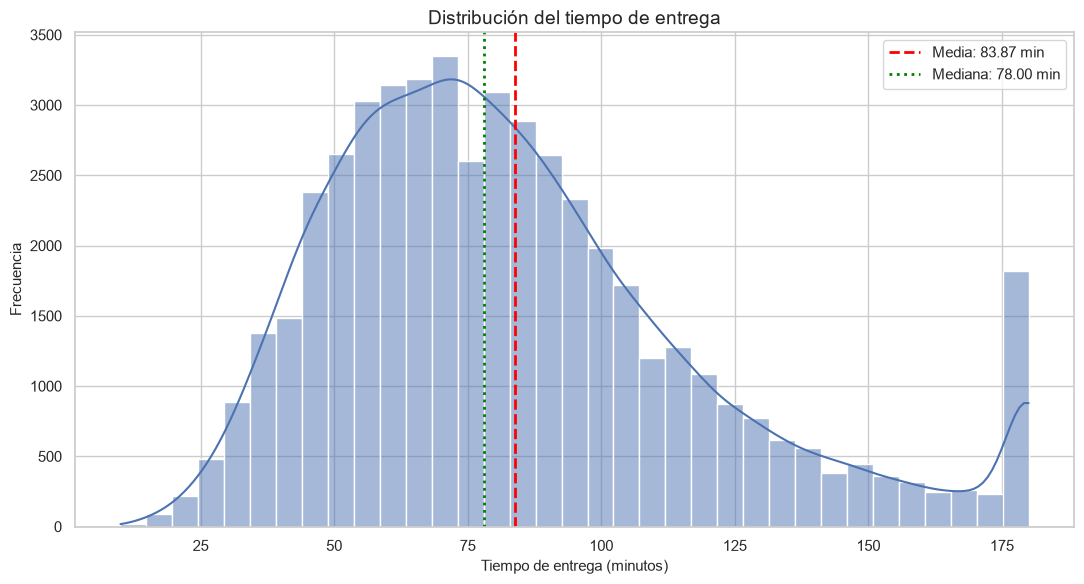

In [4]:
plt.figure(figsize=(11, 6))

sns.histplot(
    data=df,
    x=TARGET,
    bins=35,
    kde=True
)

plt.axvline(
    df[TARGET].mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Media: {df[TARGET].mean():.2f} min"
)

plt.axvline(
    df[TARGET].median(),
    color="green",
    linestyle=":",
    linewidth=2,
    label=f"Mediana: {df[TARGET].median():.2f} min"
)

plt.title("Distribución del tiempo de entrega")
plt.xlabel("Tiempo de entrega (minutos)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretación de la distribución del tiempo de entrega

La distribución del tiempo de entrega presenta una asimetría positiva, respaldada por un coeficiente de asimetría de 0,907.

La media (83,87 minutos) supera a la mediana (78 minutos), lo que indica que los tiempos de entrega elevados contribuyen a desplazar el promedio hacia valores superiores.

La desviación estándar de 35,43 minutos evidencia una dispersión considerable, con observaciones comprendidas entre 10 y 180 minutos.

Visualmente, la mayor concentración de entregas se encuentra en los valores intermedios, mientras que la distribución presenta una cola prolongada hacia tiempos superiores.

Asimismo, se observa una acumulación destacada de registros en 180 minutos, coincidente con el máximo del dataset. Este comportamiento requiere una evaluación adicional para determinar si responde a un límite de registro, una característica de la generación de datos u otro fenómeno.

En consecuencia, la variable objetivo no presenta una distribución aproximadamente simétrica, aspecto relevante para la posterior interpretación de resultados y evaluación de modelos predictivos.

In [5]:
# Evaluación de la concentración en el valor máximo

maximo_tiempo = df[TARGET].max()

cantidad_maximo = (df[TARGET] == maximo_tiempo).sum()
porcentaje_maximo = cantidad_maximo / len(df) * 100

print(f"Tiempo máximo registrado: {maximo_tiempo} minutos")
print(f"Pedidos con tiempo máximo: {cantidad_maximo:,}")
print(f"Porcentaje del dataset: {porcentaje_maximo:.2f}%")

print("\nFrecuencia de los tiempos de entrega más elevados:")
display(
    df[TARGET]
    .value_counts()
    .sort_index()
    .tail(15)
)

Tiempo máximo registrado: 180 minutos
Pedidos con tiempo máximo: 1,661
Porcentaje del dataset: 3.32%

Frecuencia de los tiempos de entrega más elevados:


Time_taken_min
166      61
167      51
168      42
169      56
170      50
171      60
172      44
173      36
174      50
175      39
176      39
177      49
178      44
179      25
180    1661
Name: count, dtype: int64

### 6.2. Distribución de la distancia recorrida

Se analiza la distribución de `Road_Distance_km` mediante un histograma con estimación de densidad KDE.

El objetivo es comprender la variabilidad de las distancias, identificar posibles asimetrías y contextualizar la elevada proporción de pedidos clasificados como entregas de larga distancia.

Este análisis permitirá posteriormente examinar la relación entre distancia y tiempo de entrega, correspondiente a la primera hipótesis de investigación.

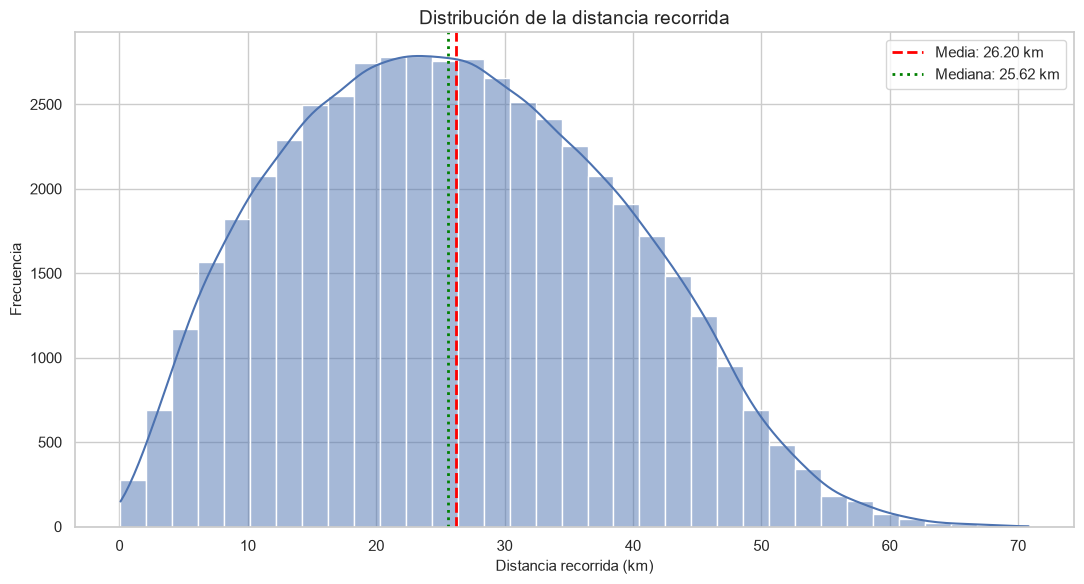

Asimetría de la distancia: 0.219


In [6]:
plt.figure(figsize=(11, 6))

sns.histplot(
    data=df,
    x="Road_Distance_km",
    bins=35,
    kde=True
)

plt.axvline(
    df["Road_Distance_km"].mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Media: {df['Road_Distance_km'].mean():.2f} km"
)

plt.axvline(
    df["Road_Distance_km"].median(),
    color="green",
    linestyle=":",
    linewidth=2,
    label=f"Mediana: {df['Road_Distance_km'].median():.2f} km"
)

plt.title("Distribución de la distancia recorrida")
plt.xlabel("Distancia recorrida (km)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Asimetría de la distancia:",
    round(df["Road_Distance_km"].skew(), 3)
)

### Hallazgo adicional: acumulación en el tiempo máximo

Se identificaron 1.661 pedidos con un tiempo de entrega exactamente igual a 180 minutos, equivalentes al 3,32 % del dataset.

Esta frecuencia contrasta notablemente con la de los valores inmediatamente anteriores; por ejemplo, solamente 25 pedidos presentan un tiempo de 179 minutos.

La acumulación en el límite superior podría estar relacionada con un mecanismo de truncamiento o limitación de los tiempos registrados. No obstante, esta interpretación requiere información adicional sobre la construcción del dataset.

Por este motivo, se conservarán los registros y se documentará esta particularidad como una limitación potencial del análisis.

### Interpretación de la distribución de la distancia recorrida

La distancia recorrida presenta una media de 26,20 km y una mediana de 25,62 km, con valores comprendidos entre 0,08 y 70,82 km.

El histograma muestra una distribución unimodal, con una concentración principal aproximadamente entre 20 y 30 km y una disminución progresiva de las frecuencias hacia distancias mayores.

La proximidad entre media y mediana indica que la distribución presenta una asimetría menos marcada que la observada en el tiempo de entrega.

Este resultado proporciona contexto para el posterior análisis de la relación entre distancia recorrida y tiempo de entrega, correspondiente a la primera hipótesis.

### 6.3. Distribución del tiempo de preparación

Se analiza la distribución de `Preparation_Time_Min` mediante un histograma con estimación de densidad KDE.

Esta variable representa el tiempo destinado a preparar el pedido y constituye uno de los factores considerados en la tercera hipótesis de investigación.

Se examinarán su tendencia central, dispersión y posibles asimetrías.

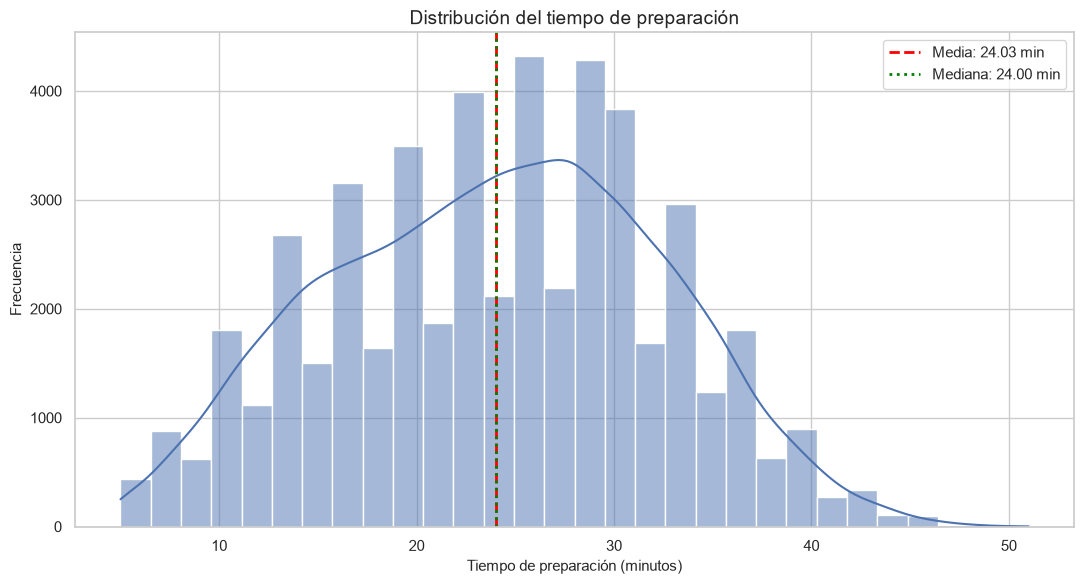

Asimetría del tiempo de preparación: -0.027


In [7]:
plt.figure(figsize=(11, 6))

sns.histplot(
    data=df,
    x="Preparation_Time_Min",
    bins=30,
    kde=True
)

plt.axvline(
    df["Preparation_Time_Min"].mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Media: {df['Preparation_Time_Min'].mean():.2f} min"
)

plt.axvline(
    df["Preparation_Time_Min"].median(),
    color="green",
    linestyle=":",
    linewidth=2,
    label=f"Mediana: {df['Preparation_Time_Min'].median():.2f} min"
)

plt.title("Distribución del tiempo de preparación")
plt.xlabel("Tiempo de preparación (minutos)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Asimetría del tiempo de preparación:",
    round(df["Preparation_Time_Min"].skew(), 3)
)

### Interpretación de la distribución del tiempo de preparación

El tiempo de preparación presenta una media de 24,03 minutos y una mediana de 24 minutos, con una desviación estándar de 8,35 minutos.

El coeficiente de asimetría de -0,027 indica una distribución prácticamente simétrica, sin una cola claramente predominante.

El histograma muestra una concentración importante de observaciones en los tiempos intermedios, aunque existen variaciones de frecuencia entre valores cercanos debido a la naturaleza discreta de la variable.

A diferencia del tiempo total de entrega, el tiempo de preparación no presenta una asimetría positiva pronunciada.

Este análisis permite caracterizar la variable antes de evaluar su relación con el tiempo total de entrega, correspondiente a la tercera hipótesis.

## 7. Análisis de valores atípicos y dispersión

Los diagramas de caja (boxplots) permiten analizar la distribución de las variables mediante la mediana, los cuartiles y el rango intercuartílico (IQR).

Los valores que se encuentran fuera de los límites convencionales de 1,5 veces el IQR se representan como posibles valores atípicos.

Sin embargo, una observación estadísticamente atípica no constituye necesariamente un error y no debe eliminarse automáticamente.

### 7.1. Boxplot del tiempo de entrega

Se analiza la dispersión de `Time_taken_min`, identificando su mediana, rango intercuartílico y posibles valores atípicos.

Se prestará especial atención a los tiempos elevados y a la acumulación previamente detectada en 180 minutos.

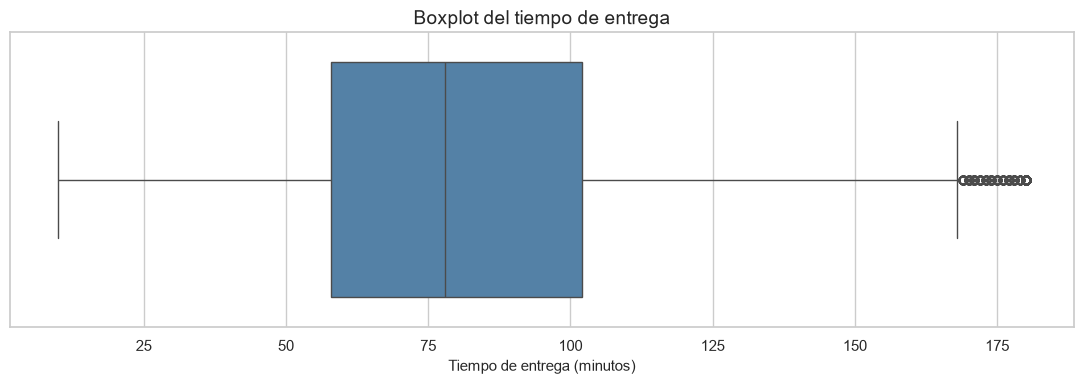

Primer cuartil (Q1): 58.00
Tercer cuartil (Q3): 102.00
Rango intercuartílico (IQR): 44.00
Límite inferior: -8.00
Límite superior: 168.00
Posibles valores atípicos: 2,153
Porcentaje: 4.31%


In [8]:
plt.figure(figsize=(11, 4))

sns.boxplot(
    data=df,
    x="Time_taken_min",
    color="steelblue"
)

plt.title("Boxplot del tiempo de entrega")
plt.xlabel("Tiempo de entrega (minutos)")
plt.tight_layout()
plt.show()

# Cálculo de los límites convencionales mediante IQR
Q1 = df[TARGET].quantile(0.25)
Q3 = df[TARGET].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df[
    (df[TARGET] < limite_inferior) |
    (df[TARGET] > limite_superior)
]

print(f"Primer cuartil (Q1): {Q1:.2f}")
print(f"Tercer cuartil (Q3): {Q3:.2f}")
print(f"Rango intercuartílico (IQR): {IQR:.2f}")
print(f"Límite inferior: {limite_inferior:.2f}")
print(f"Límite superior: {limite_superior:.2f}")
print(f"Posibles valores atípicos: {len(outliers):,}")
print(f"Porcentaje: {len(outliers) / len(df) * 100:.2f}%")

### 7.2. Boxplot de la distancia recorrida

Se analiza la dispersión de `Road_Distance_km` mediante un diagrama de caja.

El objetivo es identificar la posición de la mediana, la amplitud del rango intercuartílico y la presencia de posibles distancias atípicas.

Estas observaciones se conservarán inicialmente, ya que una distancia elevada puede representar una entrega legítima.

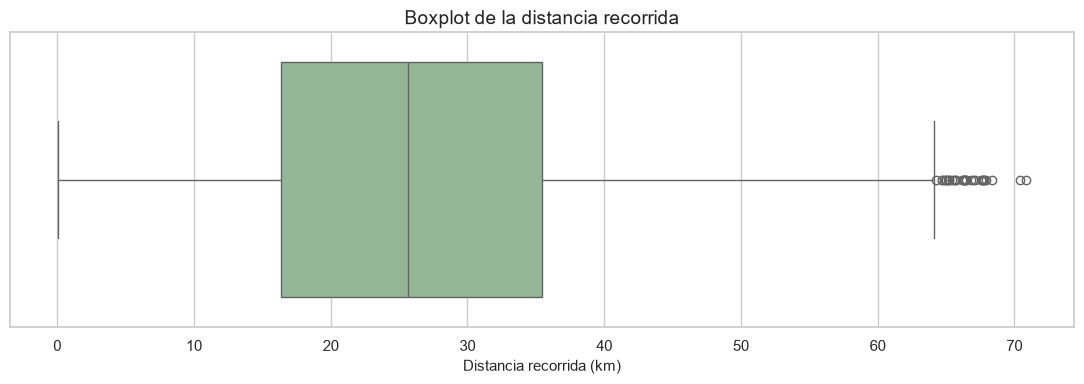

In [9]:
plt.figure(figsize=(11, 4))

sns.boxplot(
    data=df,
    x="Road_Distance_km",
    color="darkseagreen"
)

plt.title("Boxplot de la distancia recorrida")
plt.xlabel("Distancia recorrida (km)")
plt.tight_layout()
plt.show()

### 7.3. Tiempo de entrega según el nivel de tráfico

Se comparan las distribuciones del tiempo de entrega entre los diferentes niveles de tráfico.

El diagrama de caja permite examinar las diferencias en medianas, dispersión y posibles valores atípicos.

Esta comparación proporciona evidencia descriptiva para evaluar la hipótesis de que los niveles de tráfico elevados se asocian con mayores tiempos de entrega.

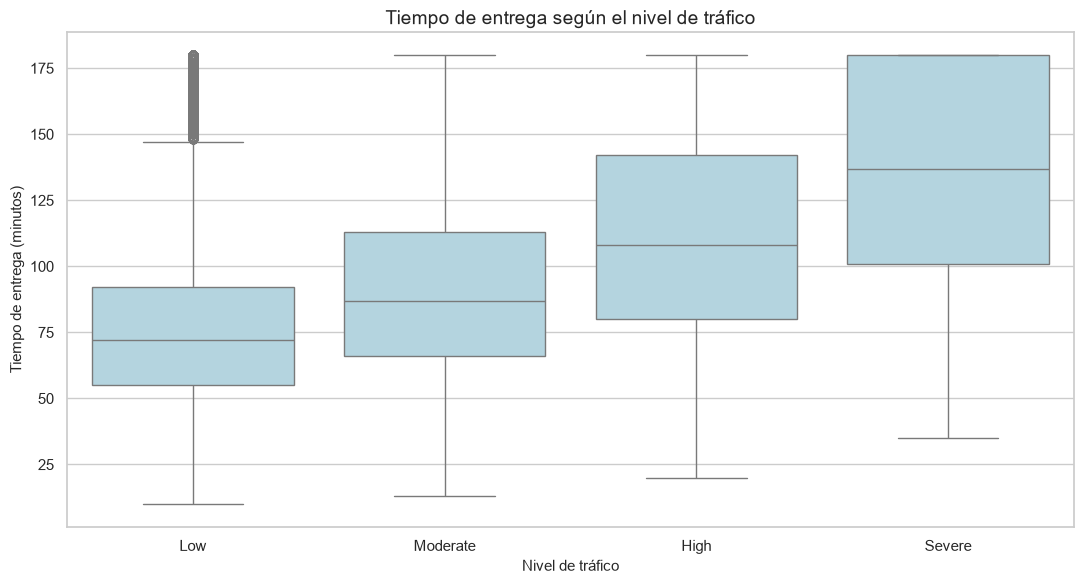

,count,mean,median,std
Traffic_Level,,,,
Low,32567,76.44,72.00,31.24
Moderate,13165,92.30,87.00,35.96
High,3744,111.73,108.00,40.48
Severe,524,134.40,137.00,39.97


In [10]:
orden_trafico = ["Low", "Moderate", "High", "Severe"]

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="Traffic_Level",
    y=TARGET,
    order=orden_trafico,
    color="lightblue"
)

plt.title("Tiempo de entrega según el nivel de tráfico")
plt.xlabel("Nivel de tráfico")
plt.ylabel("Tiempo de entrega (minutos)")
plt.tight_layout()
plt.show()

# Estadísticas por nivel de tráfico
resumen_trafico = (
    df.groupby("Traffic_Level")[TARGET]
    .agg(["count", "mean", "median", "std"])
    .reindex(orden_trafico)
    .round(2)
)

display(resumen_trafico)

### Interpretación de los valores atípicos

El tiempo de entrega presenta un primer cuartil de 58 minutos y un tercer cuartil de 102 minutos, por lo que su rango intercuartílico es de 44 minutos.

Aplicando el criterio de 1,5 veces el IQR, se obtiene un límite inferior de -8 minutos y un límite superior de 168 minutos.

Se identificaron 2.153 observaciones potencialmente atípicas, equivalentes al 4,31 % del dataset. Todas se encuentran por encima del límite superior.

Estos registros no se eliminan automáticamente, dado que pueden representar entregas excepcionalmente demoradas. No obstante, se mantiene como limitación potencial la concentración previamente identificada en el valor máximo de 180 minutos.

### Interpretación del tiempo de entrega según el tráfico

El análisis descriptivo muestra un incremento progresivo del tiempo de entrega a medida que aumenta el nivel de congestión.

El tiempo medio pasa de 76,44 minutos con tráfico bajo a 134,40 minutos con tráfico severo. Las medianas presentan un comportamiento similar, aumentando de 72 a 137 minutos.

Estos resultados proporcionan evidencia descriptiva favorable a la hipótesis 2, según la cual las condiciones de tráfico más congestionadas se asocian con mayores tiempos de entrega.

Sin embargo, los grupos presentan tamaños considerablemente diferentes y la asociación observada no demuestra una relación causal. La influencia conjunta de otras variables deberá considerarse al interpretar estos resultados.

## 8. Análisis de relaciones entre variables numéricas

Los gráficos de dispersión permiten explorar la asociación entre dos variables numéricas, identificar tendencias generales y reconocer posibles relaciones no lineales.

### 8.1. Distancia recorrida y tiempo de entrega

Se analiza la relación entre `Road_Distance_km` y `Time_taken_min`, correspondiente a la primera hipótesis.

Se utiliza un gráfico de dispersión acompañado de una línea de tendencia lineal con fines descriptivos.

La intensidad de la asociación se complementa con el coeficiente de correlación de Pearson.

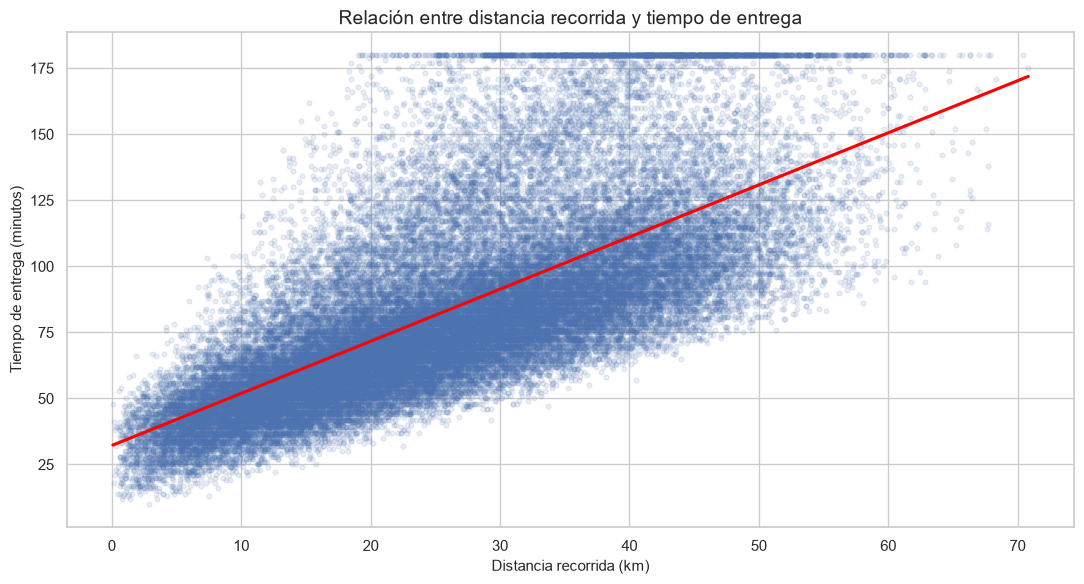

Correlación de Pearson: 0.703


In [11]:
plt.figure(figsize=(11, 6))

sns.regplot(
    data=df,
    x="Road_Distance_km",
    y=TARGET,
    scatter_kws={"alpha": 0.12, "s": 12},
    line_kws={"color": "red"},
    ci=None
)

plt.title("Relación entre distancia recorrida y tiempo de entrega")
plt.xlabel("Distancia recorrida (km)")
plt.ylabel("Tiempo de entrega (minutos)")
plt.tight_layout()
plt.show()

correlacion_distancia = df[
    ["Road_Distance_km", TARGET]
].corr().iloc[0, 1]

print(f"Correlación de Pearson: {correlacion_distancia:.3f}")

### 8.2. Tiempo de preparación y tiempo de entrega

Se analiza la asociación entre `Preparation_Time_Min` y `Time_taken_min`, correspondiente a la tercera hipótesis.

El gráfico permitirá evaluar si los pedidos que requieren más tiempo de preparación tienden a presentar mayores tiempos totales de entrega.

Se incorpora una línea de tendencia y se calcula la correlación de Pearson para complementar la interpretación visual.

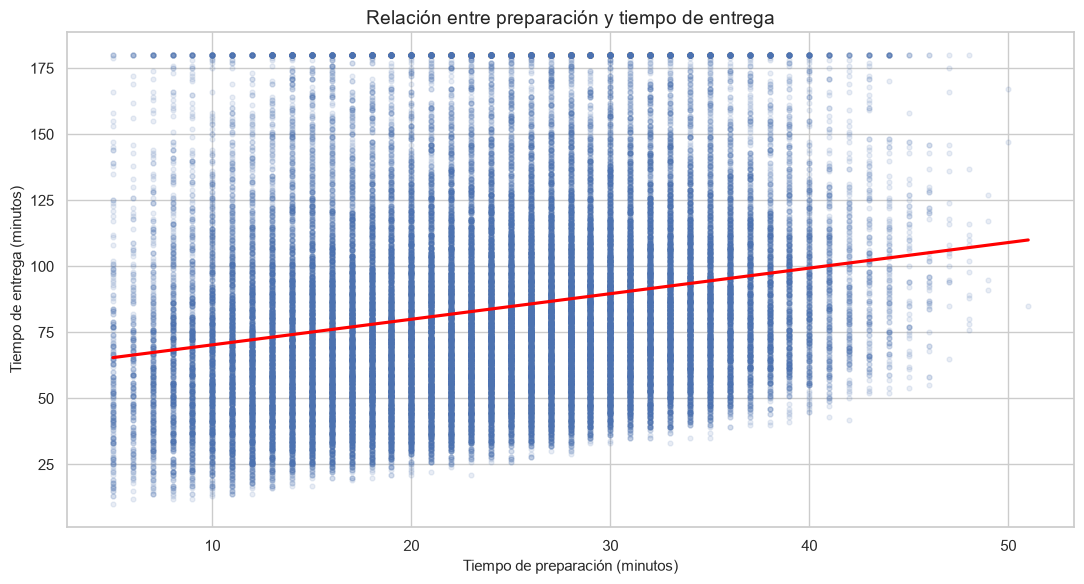

Correlación de Pearson: 0.228


In [12]:
plt.figure(figsize=(11, 6))

sns.regplot(
    data=df,
    x="Preparation_Time_Min",
    y=TARGET,
    scatter_kws={"alpha": 0.12, "s": 12},
    line_kws={"color": "red"},
    ci=None
)

plt.title("Relación entre preparación y tiempo de entrega")
plt.xlabel("Tiempo de preparación (minutos)")
plt.ylabel("Tiempo de entrega (minutos)")
plt.tight_layout()
plt.show()

correlacion_preparacion = df[
    ["Preparation_Time_Min", TARGET]
].corr().iloc[0, 1]

print(f"Correlación de Pearson: {correlacion_preparacion:.3f}")

### Interpretación: distancia y tiempo de entrega

El gráfico de dispersión evidencia una asociación positiva entre la distancia recorrida y el tiempo total de entrega.

El coeficiente de correlación de Pearson obtenido fue **r = 0,703**, lo que indica una asociación lineal positiva fuerte.

La tendencia ascendente muestra que los pedidos de mayor distancia tienden a presentar mayores tiempos de entrega. Sin embargo, existe dispersión entre las observaciones, lo que sugiere que también intervienen otros factores.

Se observa nuevamente una acumulación de registros en el límite superior de 180 minutos.

**Conclusión de la hipótesis 1:** los resultados proporcionan evidencia descriptiva favorable a la hipótesis de que mayores distancias se asocian con mayores tiempos de entrega. Esta asociación no demuestra causalidad.

### Interpretación: preparación y tiempo de entrega

El gráfico de dispersión muestra una tendencia positiva entre el tiempo de preparación y el tiempo total de entrega.

El coeficiente de correlación de Pearson fue **r = 0,228**, lo que indica una asociación lineal positiva débil.

La dispersión considerable de los puntos evidencia que pedidos con tiempos de preparación similares pueden presentar tiempos totales muy diferentes.

Las franjas verticales observadas corresponden al carácter discreto de `Preparation_Time_Min`, cuyos valores se registran en minutos enteros.

**Conclusión de la hipótesis 3:** los resultados proporcionan evidencia descriptiva favorable a la dirección propuesta, aunque la asociación lineal es débil. No es posible establecer causalidad a partir de este análisis.

## 9. Visualizaciones complementarias

### 9.1. Mapa de calor de correlaciones

Se construye una matriz de correlaciones de Pearson para examinar las asociaciones lineales entre las principales variables numéricas del dataset.

El mapa de calor permite comparar la dirección y la intensidad de las relaciones, identificar posibles redundancias entre variables y complementar las hipótesis previamente analizadas.

Se incluye la velocidad promedio para evaluar descriptivamente la hipótesis 4.

Las correlaciones no deben interpretarse como relaciones causales.

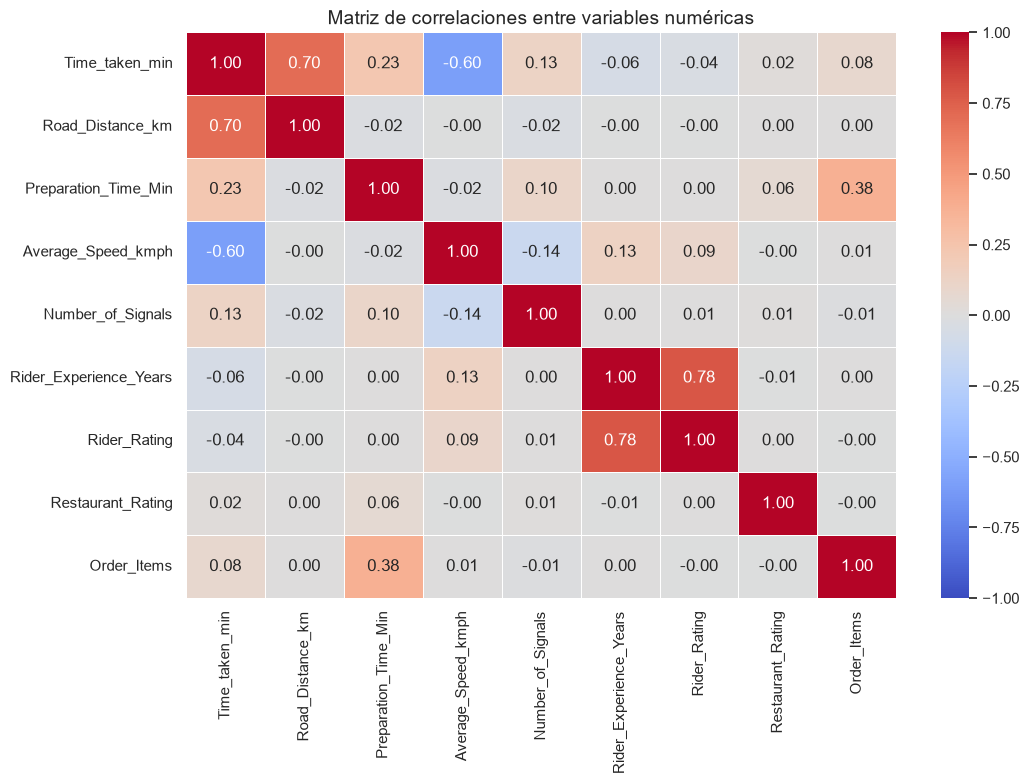

Correlaciones con el tiempo de entrega:


Time_taken_min            1.00
Road_Distance_km          0.70
Preparation_Time_Min      0.23
Number_of_Signals         0.13
Order_Items               0.08
Restaurant_Rating         0.02
Rider_Rating             -0.04
Rider_Experience_Years   -0.06
Average_Speed_kmph       -0.60
Name: Time_taken_min, dtype: float64

In [13]:
variables_correlacion = [
    "Time_taken_min",
    "Road_Distance_km",
    "Preparation_Time_Min",
    "Average_Speed_kmph",
    "Number_of_Signals",
    "Rider_Experience_Years",
    "Rider_Rating",
    "Restaurant_Rating",
    "Order_Items"
]

matriz_correlacion = df[variables_correlacion].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Matriz de correlaciones entre variables numéricas")
plt.tight_layout()
plt.show()

print("Correlaciones con el tiempo de entrega:")

display(
    matriz_correlacion["Time_taken_min"]
    .sort_values(ascending=False)
    .round(3)
)

### Interpretación de la matriz de correlaciones

El análisis de correlaciones de Pearson permitió identificar las principales asociaciones lineales entre las variables numéricas y el tiempo total de entrega.

La distancia recorrida presenta la asociación positiva más elevada (`r = 0,70`), mientras que la velocidad promedio muestra una asociación negativa considerable (`r = -0,60`).

El tiempo de preparación presenta una correlación positiva débil (`r = 0,23`), mientras que el número de señales de tránsito (`r = 0,13`) y la cantidad de artículos del pedido (`r = 0,08`) muestran asociaciones lineales de menor intensidad.

Las calificaciones del restaurante y del repartidor, así como la experiencia del repartidor, presentan correlaciones cercanas a cero con el tiempo de entrega.

**Conclusión de la hipótesis 4:** los resultados proporcionan evidencia descriptiva favorable a la existencia de una asociación negativa entre la velocidad promedio y el tiempo de entrega.

Sin embargo, la velocidad promedio podría no conocerse al momento de realizar una predicción. Por ello, su eventual utilización como variable predictora deberá evaluarse considerando el riesgo de fuga de información (*data leakage*).

Estas correlaciones son bivariadas y no permiten establecer relaciones causales ni aislar el efecto de otras variables.

### 9.2. Tiempo de entrega según condiciones climáticas

Se analiza el tiempo promedio de entrega según las categorías de la variable `Weather`.

El objetivo es identificar posibles diferencias descriptivas entre condiciones climáticas y evaluar si estas podrían estar asociadas con variaciones en los tiempos de entrega.

Se utilizará un gráfico de barras ordenado según el tiempo promedio, acompañado de una tabla con la cantidad de pedidos, la media y la mediana de cada categoría.

,count,mean,median,std
Weather,,,,
Storm,2437,114.45,111.00,41.38
Rain,9073,98.86,94.00,38.66
Fog,3413,84.15,79.00,34.78
Cloudy,11085,79.02,74.00,32.25
Clear,23992,77.30,73.00,31.46


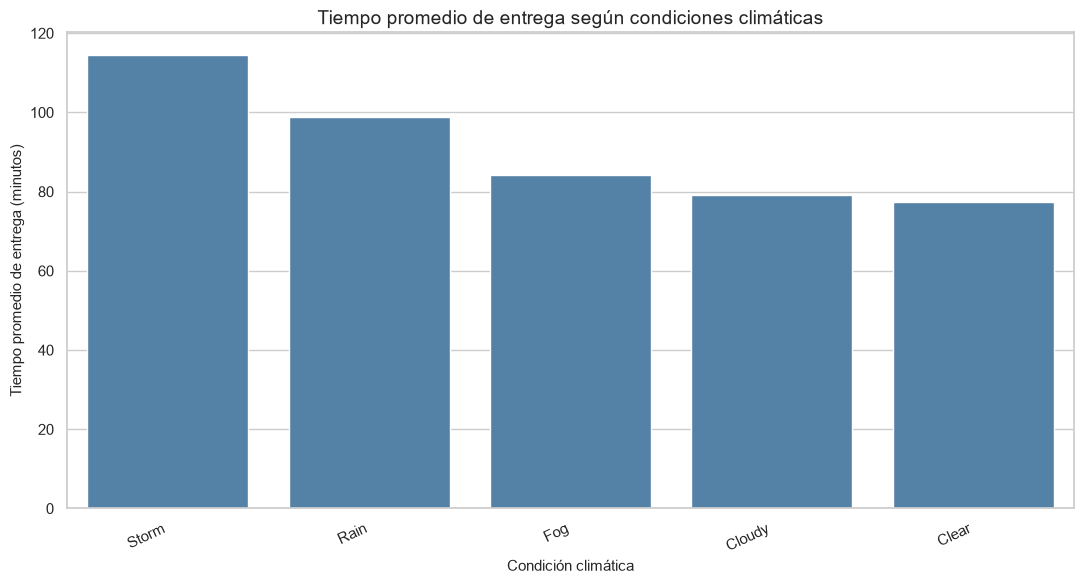

In [14]:
# Resumen estadístico por condición climática
resumen_clima = (
    df.groupby("Weather")[TARGET]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
    .round(2)
)

display(resumen_clima)

# Gráfico de barras con las medias observadas
plt.figure(figsize=(11, 6))

sns.barplot(
    data=resumen_clima.reset_index(),
    x="Weather",
    y="mean",
    color="steelblue",
    errorbar=None
)

plt.title("Tiempo promedio de entrega según condiciones climáticas")
plt.xlabel("Condición climática")
plt.ylabel("Tiempo promedio de entrega (minutos)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 9.3. Evolución del tiempo promedio de entrega según la hora del pedido

Se analiza cómo varía el tiempo promedio de entrega a lo largo de las 24 horas del día.

La variable `Order_Hour` permite examinar patrones temporales y detectar franjas horarias asociadas con mayores o menores tiempos de entrega.

Se utilizará un gráfico de líneas con las horas ordenadas cronológicamente y una tabla de estadísticas descriptivas.

Las diferencias observadas serán interpretadas como asociaciones descriptivas, sin atribuirlas automáticamente a factores causales.

,count,mean,median
Order_Hour,,,
0,463,83.12,76.00
1,471,80.99,77.00
2,463,79.34,74.00
3,507,80.74,74.00
4,490,80.24,75.00
5,956,80.47,76.00
6,1985,80.77,76.00
7,2471,81.50,76.00
8,2476,87.70,81.00


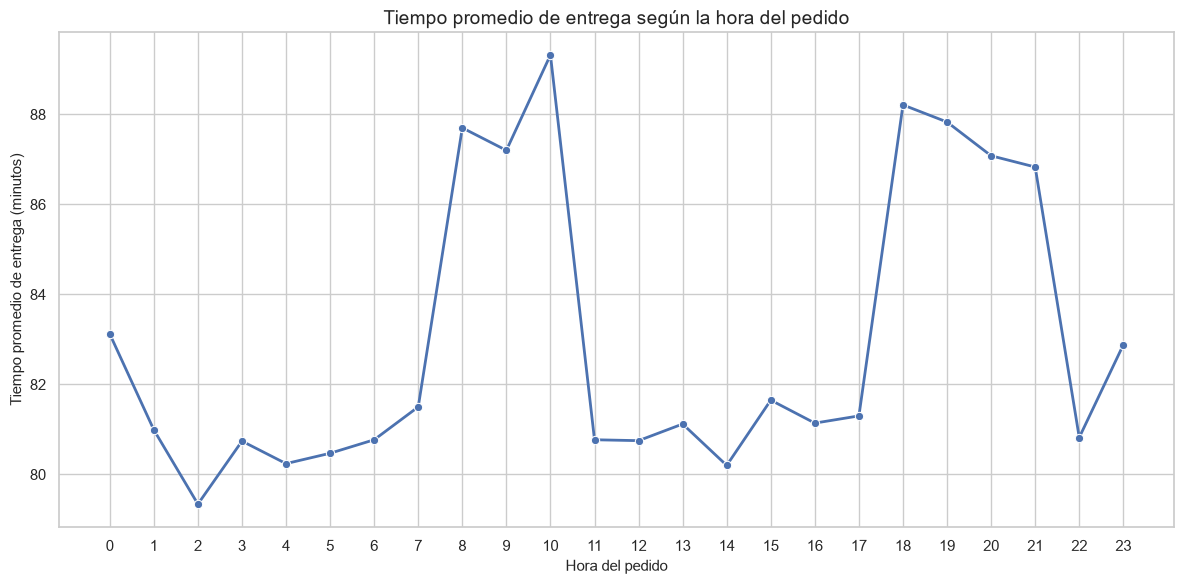

In [15]:
# Resumen por hora del pedido
resumen_horas = (
    df.groupby("Order_Hour")[TARGET]
    .agg(["count", "mean", "median"])
    .sort_index()
    .round(2)
)

display(resumen_horas)

# Gráfico de líneas
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=resumen_horas.reset_index(),
    x="Order_Hour",
    y="mean",
    marker="o",
    linewidth=2
)

plt.title("Tiempo promedio de entrega según la hora del pedido")
plt.xlabel("Hora del pedido")
plt.ylabel("Tiempo promedio de entrega (minutos)")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

### Interpretación del tiempo de entrega según el clima

El análisis descriptivo evidencia diferencias en los tiempos de entrega según las condiciones climáticas.

Los pedidos realizados bajo condiciones despejadas presentan el menor tiempo medio (77,30 minutos), seguidos por condiciones nubladas (79,02 minutos), niebla (84,15 minutos), lluvia (98,86 minutos) y tormentas (114,45 minutos).

La diferencia entre condiciones despejadas y tormentas alcanza los 37,15 minutos en promedio.

Asimismo, la desviación estándar aumenta de 31,46 minutos con clima despejado a 41,38 minutos durante tormentas, lo que indica una mayor dispersión en este último grupo.

Estos resultados sugieren una asociación descriptiva entre condiciones climáticas adversas y mayores tiempos de entrega. Sin embargo, no permiten establecer causalidad ni descartar la influencia de otras variables.

### Interpretación del tiempo de entrega según la hora

El análisis horario muestra variaciones en el tiempo promedio de entrega a lo largo del día.

El mayor promedio se registra a las 10:00 (89,32 minutos), mientras que el menor corresponde a las 02:00 (79,34 minutos).

Se observan valores relativamente elevados durante las franjas de 08:00 a 10:00 y de 18:00 a 21:00.

Estas diferencias podrían estar relacionadas con cambios en las condiciones operativas, la demanda o el tráfico. Sin embargo, dichas explicaciones constituyen hipótesis adicionales que no pueden confirmarse únicamente mediante este gráfico.

Además, la cantidad de pedidos varía considerablemente entre horas, por lo que los promedios deben interpretarse teniendo en cuenta el tamaño de cada grupo.

En conjunto, los resultados muestran que el tiempo de entrega presenta variaciones asociadas con la hora del pedido.

## 10. Evaluación complementaria de las condiciones operativas

Para completar la evaluación de la quinta hipótesis, se examinan las diferencias en los tiempos de entrega según la carga del restaurante y la prioridad asignada al pedido.

Se utilizan estadísticas descriptivas por categoría, incluyendo cantidad de registros, media, mediana y desviación estándar.

Este análisis complementa las visualizaciones de clima y horario, permitiendo evaluar la hipótesis desde distintas dimensiones operativas.

In [16]:
variables_operativas = [
    "Restaurant_Load",
    "Delivery_Priority"
]

for variable in variables_operativas:
    print(f"\n=== {variable} ===")

    resumen = (
        df.groupby(variable)[TARGET]
        .agg(["count", "mean", "median", "std"])
        .sort_values("mean", ascending=False)
        .round(2)
    )

    display(resumen)


=== Restaurant_Load ===


,count,mean,median,std
Restaurant_Load,,,,
High,15799,86.07,80.00,35.32
Medium,16450,83.60,78.00,35.48
Low,17751,82.16,76.00,35.37



=== Delivery_Priority ===


,count,mean,median,std
Delivery_Priority,,,,
Normal,37065,84.17,78.00,35.36
Priority,9916,83.28,77.00,35.76
VIP,3019,82.10,76.00,35.10


### Interpretación de las condiciones operativas

El análisis de la carga del restaurante muestra un incremento progresivo del tiempo medio de entrega: 82,16 minutos con carga baja, 83,60 minutos con carga media y 86,07 minutos con carga alta.

La diferencia entre los extremos es de 3,91 minutos, lo que representa una asociación descriptiva de magnitud relativamente reducida frente a la dispersión general de los tiempos.

Por otra parte, la prioridad de entrega presenta una tendencia inversa: los pedidos normales registran una media de 84,17 minutos, los prioritarios de 83,28 minutos y los VIP de 82,10 minutos.

La diferencia entre pedidos normales y VIP es de 2,07 minutos.

Estos resultados sugieren que una mayor carga del restaurante se asocia con tiempos ligeramente superiores y que las prioridades más altas se asocian con tiempos ligeramente inferiores.

Sin embargo, las diferencias observadas son pequeñas y no permiten establecer relaciones causales ni determinar si resultan estadísticamente significativas.

En conjunto, estas observaciones complementan la evidencia obtenida sobre las condiciones climáticas y las variaciones horarias.

## 11. Evaluación de las hipótesis de investigación

A continuación, se sintetizan los resultados obtenidos mediante el análisis estadístico descriptivo y las visualizaciones.

### Hipótesis 1 — Distancia y tiempo de entrega

**Resultado: respaldada descriptivamente.**

Se identificó una correlación lineal positiva fuerte entre la distancia recorrida y el tiempo de entrega (r = 0,703).

El gráfico de dispersión confirmó una tendencia ascendente: las entregas de mayor distancia tienden a presentar tiempos superiores.

La distancia constituye una de las variables numéricas con mayor asociación lineal con el tiempo de entrega.

### Hipótesis 2 — Congestión del tráfico

**Resultado: respaldada descriptivamente.**

Los tiempos medios aumentan progresivamente según el nivel de congestión:

- Low: 76,44 minutos.
- Moderate: 92,30 minutos.
- High: 111,73 minutos.
- Severe: 134,40 minutos.

La diferencia media entre tráfico bajo y severo es de 57,96 minutos.

Los resultados evidencian una asociación descriptiva clara entre mayor congestión y mayores tiempos de entrega.

### Hipótesis 3 — Tiempo de preparación

**Resultado: respaldada parcialmente.**

El tiempo de preparación presenta una correlación positiva débil con el tiempo de entrega (r = 0,228).

Aunque la dirección de la asociación coincide con la hipótesis, la dispersión observada indica que el tiempo de preparación, considerado individualmente, mantiene una relación lineal limitada con el tiempo total.

### Hipótesis 4 — Velocidad promedio

**Resultado: respaldada descriptivamente.**

Se identificó una correlación negativa considerable entre la velocidad promedio y el tiempo de entrega (r ≈ -0,60).

Los registros con mayores velocidades promedio tienden a presentar menores tiempos de entrega.

No obstante, esta variable podría no estar disponible al momento de realizar una predicción y deberá evaluarse cuidadosamente antes de utilizarse en un modelo.

### Hipótesis 5 — Condiciones operativas y temporales

**Resultado: respaldada descriptivamente, con diferencias de magnitud variable.**

Las condiciones climáticas presentan diferencias relevantes: el tiempo medio aumenta desde 77,30 minutos con clima despejado hasta 114,45 minutos durante tormentas.

El análisis horario identifica tiempos relativamente elevados entre las 08:00 y las 10:00 y entre las 18:00 y las 21:00.

La carga del restaurante también presenta una asociación positiva con el tiempo de entrega, aunque de menor magnitud: la diferencia entre carga alta y baja es de 3,91 minutos.

Por su parte, los pedidos VIP registran un tiempo medio 2,07 minutos inferior al de los pedidos normales.

En conjunto, las condiciones operativas y temporales presentan asociaciones descriptivas con los tiempos de entrega, pero sus magnitudes son diferentes.

### Consideración metodológica

Las hipótesis se evaluaron mediante estadística descriptiva, correlaciones y visualizaciones exploratorias.

Por lo tanto, los resultados no constituyen pruebas de causalidad ni implican, por sí solos, significación estadística.

## 12. Conclusiones generales

El análisis exploratorio permitió caracterizar un dataset de 50.000 pedidos de entrega de comida correspondientes al año 2025, compuesto por 24 variables de naturaleza numérica, categórica y temporal.

La evaluación inicial de calidad no identificó valores faltantes, registros completamente duplicados ni inconsistencias en las fechas y sus variables temporales asociadas.

El tiempo de entrega presenta una media de 83,87 minutos, una mediana de 78 minutos y una desviación estándar de 35,43 minutos. Su distribución muestra asimetría positiva, con una concentración relevante de observaciones en el límite superior de 180 minutos.

Los resultados permiten destacar los siguientes hallazgos:

1. La distancia recorrida presenta una asociación lineal positiva fuerte con el tiempo de entrega.
2. Los tiempos medios aumentan progresivamente con el nivel de congestión del tráfico.
3. Las condiciones climáticas adversas se asocian con mayores tiempos de entrega.
4. La velocidad promedio presenta una asociación negativa considerable con el tiempo de entrega.
5. El tiempo de preparación, la carga del restaurante, la prioridad del pedido y la hora del día también presentan asociaciones descriptivas, aunque de diferente magnitud.

### 12.1. Limitaciones del análisis

El estudio presenta limitaciones que deben considerarse al interpretar sus resultados:

- **Naturaleza observacional:** las asociaciones identificadas no demuestran causalidad.
- **Acumulación en 180 minutos:** 1.661 pedidos (3,32 %) presentan exactamente el valor máximo, lo que podría indicar un mecanismo de limitación o truncamiento de los datos.
- **Desequilibrio de categorías:** el 94,48 % de los pedidos pertenece a la categoría de distancia Long.
- **Diferencias en los tamaños de grupo:** algunas categorías, como tráfico severo, contienen considerablemente menos observaciones.
- **Disponibilidad de predictores:** determinadas variables, como la velocidad promedio, podrían conocerse únicamente durante o después de la entrega, lo que plantea un posible riesgo de fuga de información en modelos predictivos.
- **Alcance temporal:** el dataset corresponde al año 2025 y no permite garantizar que las asociaciones observadas se mantengan en otros períodos o contextos.

### 12.2. Conclusión final

El análisis exploratorio permitió responder las cinco hipótesis planteadas e identificar patrones relevantes en los tiempos de entrega.

La distancia, el tráfico, el clima y la velocidad promedio destacan por sus asociaciones descriptivas con la duración de las entregas.

Los resultados proporcionan una base para comprender el comportamiento del dataset y orientar futuros análisis predictivos, siempre que se controle la disponibilidad temporal de las variables y se evalúe la capacidad de generalización de los modelos.

En consecuencia, se considera cumplido el objetivo del análisis exploratorio: caracterizar los datos, evaluar su calidad, identificar distribuciones y valores atípicos, estudiar relaciones entre variables y formular conclusiones fundamentadas en la evidencia disponible.